In [1]:
# Initialisation
#  echo: false
# Recharge automatiquement les modules modifiés (évite de redémarrer le kernel)
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.signal as sci
from scipy.signal import hilbert
from scipy.stats import kurtosis
from scipy.fftpack import fft, fftfreq
from IPython.display import Markdown

# Cherche le dossier racine du projet (BDS_Fault_Detection) pour faire les imports depuis Sources/
dossier = Path().resolve()
for parent in (dossier, *dossier.parents):
    if "BDS_Fault_Detection" in parent.name:
        RACINE = parent
sys.path.insert(0, str(RACINE))

# Importation des fonctions du projet (dossier Sources/). Attention de l'ordre d'importation  !
from Sources import data, config, signaux, indicateurs, features, models


I0000 00:00:1795600945.820418   45573 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
# Sélection du scope de données à traiter (sources, défauts, diamètres, positions, charges, canaux)
selection = data.selectionner(
    sources=("12kDE", "Normal"),
    defauts=("IR", "B", "OR"),
    diametres=(7, 14, 21), positions_or=("6",),
    charges=(0, 1, 2, 3),
    canaux={"12kDE": ("DE",), 
            "Normal": ("DE")},
)

In [3]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from Sources.data import selectionner, charger
from Sources.config import DUREE_FENETRE

def construire_fenetres_brutes(selection, canal="DE", duree=0.17067, recouvrement=0.5):
    """R
    duree=0.17067 >> correspond à 2048 points
    envoie (SB, infos) : signaux BRUTS (pas encore normalisés) + infos par fenetre.
    Fenetre plus petite = entrainement moins long sans perte d'information
    Plus de fenêtre = modèle mieux entrainé
    """
    SB, lignes = [], []
    for nom, info in selection.iterrows():
        s = charger(nom)
        for i, val in enumerate(features.fenetrer(s[canal], s["fs"], duree=duree, recouvrement=recouvrement)):
            SB.append(val)                                   # brut, sans normaliser
            lignes.append({"fichier": nom, "fenetre": i, "canal": canal,
                           "defaut": info["defaut"], "charge_hp": info["charge_hp"],
                           "rpm": s["rpm"], "fs": s["fs"]})
    return np.array(SB, dtype=np.float32), pd.DataFrame(lignes)

SB, infos = construire_fenetres_brutes(selection, canal="DE")

In [4]:
# Le tableau complet, une fois pour toutes : infos d'abord, puis les valeurs s0..sN
tableau = pd.concat([infos.reset_index(drop=True),
                     pd.DataFrame(SB, columns=[f"s{i}" for i in range(SB.shape[1])])], axis=1)

tableau.head()

,fichier,fenetre,canal,defaut,charge_hp,rpm,fs,s0,s1,s2,...,s2038,s2039,s2040,s2041,s2042,s2043,s2044,s2045,s2046,s2047
0,Normal_L0,0,DE,Sain,0,1796.0,12000,0.053197,0.088662,0.099718,...,-0.039637,-0.017315,-0.023574,-0.034004,-0.044852,-0.038802,-0.016689,0.000209,-0.021905,-0.071138
1,Normal_L0,1,DE,Sain,0,1796.0,12000,0.134766,0.085115,0.015020,...,0.114113,0.061333,0.017315,-0.008553,0.006676,0.027954,0.028372,0.027746,0.020236,0.042349
2,Normal_L0,2,DE,Sain,0,1796.0,12000,-0.095546,-0.091374,-0.056535,...,-0.118076,-0.145405,-0.099301,-0.050902,-0.001252,0.049859,0.104308,0.155210,0.168561,0.146657
3,Normal_L0,3,DE,Sain,0,1796.0,12000,0.055909,0.035882,0.003755,...,0.134766,0.136852,0.063836,-0.018358,-0.077605,-0.089287,-0.074058,-0.070929,-0.065505,-0.049442
4,Normal_L0,4,DE,Sain,0,1796.0,12000,0.065714,-0.031710,-0.089496,...,-0.025660,-0.127881,-0.157296,-0.149994,-0.101804,-0.039637,0.003129,0.039846,0.056118,0.047564


# Preprocessing
1. Fenêtrage par recouvrement
On créer des fenêtres dans le signal pour avoir d'avantage de données d'entrainement (comme précédement).
On veille à avoir des fenêtres assez longue pour ne pas perdre d'informations.

2. Le recouvrement sert à mieux capter les chocs :
Sans recouvrement, un choc de défaut qui tomberait à cheval sur le partage de deux fenêtres est vue "à moitié" dans chaque fenêtre, le modèle verrait donc moins bien l'événement "choc". Avec du recouvrement, chaque événement apparaît complet dans au moins une fenêtre, on ne perd pas d'information.

3. Normalisation
On normalise le signal brut car l'amplitude peut varier (notamment avec la charge) et on cherche à capter les variations des signaux (les chocs), pas les valeurs absolues du signal.
Si la charge augmente, l'amplitude du signal (de la fenêtre) augmente, et le modèle va détecter une variation et donc un défaut, hors l'augmentation de charge n'est pas un défaut !

In [5]:
# Split PAR FICHIER + masque "sain" pour l'entrainement
from sklearn.model_selection import GroupShuffleSplit

gss = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=42)
# Split et on récupère les index du train et test
i_train, i_test = next(gss.split(infos, groups=infos["fichier"]))

# Masque sur les données saines
sain = (infos["defaut"] == "Sain").to_numpy()

# Standardisation 
SBNorm = features.standardiser_par_fenetre(SB) # z-score par fenêtre, sans état : aucune fuite

# Uniquement les données saine, avec les index i_train
X_train_sain = SBNorm[i_train][sain[i_train]]         # Le train ne comporte que les données saines !

In [6]:
# tableau.iloc[i_train].head()      # Table train
# tableau.iloc[i_train[sain[i_train]]].head()                 # sain train
print("=== Nombre de fenêtres du plan de test ===")
pd.DataFrame({
    "train": tableau.iloc[i_train[sain[i_train]]]["defaut"].value_counts(),
    "test":  tableau.iloc[i_test]["defaut"].value_counts(),
}).fillna(0).astype(int)


=== Nombre de fenêtres du plan de test ===


,train,test
defaut,,
B,0,235
IR,0,470
OR,0,235
Sain,709,944


In [7]:
# ---------------------------------------------------------------
# 3. Conv1D-AE minimal (Keras) + score d'anomalie = MSE
# ---------------------------------------------------------------
import tensorflow as tf
import keras
from keras import layers

def conv1d_ae(taille=SB.shape[1]):
    Input = keras.Input(shape=(taille, 1))
    # Encodeur : 2 poolings
    x = layers.Conv1D(32, 7, activation="relu", padding="same")(Input) 
    x = layers.MaxPooling1D(2, padding="same")(x)                       
    x = layers.Conv1D(16, 5, activation="relu", padding="same")(x)      
    x = layers.MaxPooling1D(2, padding="same")(x)                       
    latent = layers.Conv1D(8, 3, activation="relu", padding="same")(x)
    # Decodeur : miroir exact
    x = layers.Conv1D(16, 5, activation="relu", padding="same")(latent)  
    x = layers.UpSampling1D(2)(x)                                         
    x = layers.Conv1D(32, 7, activation="relu", padding="same")(x)        
    x = layers.UpSampling1D(2)(x)                                       
    sortie = layers.Conv1D(1, 7, padding="same")(x)           
    modele = keras.Model(Input, sortie)
    modele.compile(optimizer="adam", loss="mse")
    return modele

In [8]:
modele = conv1d_ae()
modele.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 2048, 1)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 2048, 32)       │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 1024, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 1024, 16)       │         2,576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 512, 16)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 512, 8)         │           392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_3 (Conv1D)               │ (None, 512, 16)        │           656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling1d (UpSampling1D)    │ (None, 1024, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_4 (Conv1D)               │ (None, 1024, 32)       │         3,616 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling1d_1 (UpSampling1D)  │ (None, 2048, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_5 (Conv1D)               │ (None, 2048, 1)        │           225 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,721 (30.16 KB)

 Trainable params: 7,721 (30.16 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:
from keras.callbacks import EarlyStopping

ES = EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True, min_delta=0.01) 
    # min_delta élevé ajouté pour arrêter rapidmeent l'apprentissage, car globalement les progrès sont mince après la 10ème époque

# [..., None] >> On ajoute une colonne à la fin :
# C'est la forme exigée par Conv1D : (batch, longueur, canaux) d'où le 1 (un seul canal : le signal vibratoire).
hist = modele.fit(X_train_sain[..., None], X_train_sain[..., None],
                  epochs=50, batch_size=64, validation_split=0.1, verbose=1,
                  callbacks=[ES])

Epoch 1/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 9s 530ms/step - loss: 0.9132 - val_loss: 0.7653
Epoch 2/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 196ms/step - loss: 0.5745 - val_loss: 0.3972
Epoch 3/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 184ms/step - loss: 0.2873 - val_loss: 0.2820
Epoch 4/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 205ms/step - loss: 0.2131 - val_loss: 0.2540
Epoch 5/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 187ms/step - loss: 0.1879 - val_loss: 0.2369
Epoch 6/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 177ms/step - loss: 0.1756 - val_loss: 0.2248
Epoch 7/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 178ms/step - loss: 0.1656 - val_loss: 0.2120
Epoch 8/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 184ms/step - loss: 0.1556 - val_loss: 0.1957
Epoch 9/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 176ms/step - loss: 0.1413 - val_loss: 0.1683
Epoch 10/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 200ms/step - loss: 0.1135 - val_loss: 0.1125
Epoch 11/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 189ms/step - loss: 0.0683 - val_loss: 0.0500
Epoch 12/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 183ms/step

In [10]:
# score d'anomalie MSE : erreur de reconstruction par fenetre
def score_anomalie(modele, SBNorm):
    Xr = modele.predict(SBNorm[..., None], verbose=1)[..., 0]
    return ((SBNorm - Xr) ** 2).mean(axis=1)            # Calcul de la MSE, notre score ici.

# On écrit les score dans infos
infos["score"] = score_anomalie(modele, SBNorm)

# On fixe le seuil d'alerte par rapport au score en (donc presque le max)
seuilPourcent = 99
seuil = np.percentile(infos["score"].to_numpy()[i_train][sain[i_train]], seuilPourcent )

# Si on veut modifier facilement la marge, pour voir les effets sur les scores
# seuil = seuil*1.2
# Seuil haut > Moins d'alerte // Plus de risque
# Seuil bas > plus d'alertes // moins de risque

# On écrit s'il y a une alarme sur base de ce seuil dans infos
infos["alarme"] = infos["score"] > seuil

W0000 00:00:1795601009.608342   45573 cpu_allocator_impl.cc:174] Allocation of 48226304 exceeds 10% of free system memory.


184/184 ━━━━━━━━━━━━━━━━━━━━ 5s 27ms/step


W0000 00:00:1795601015.129185   45573 cpu_allocator_impl.cc:174] Allocation of 48226304 exceeds 10% of free system memory.


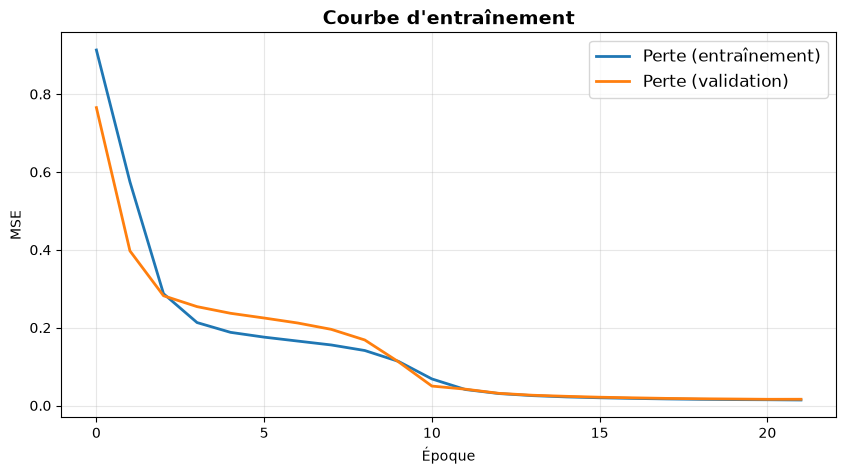

In [11]:
plt.figure(figsize=(10, 5))
plt.plot(hist.history["loss"], label="Perte (entraînement)", linewidth=2)
plt.plot(hist.history["val_loss"], label="Perte (validation)", linewidth=2)
plt.xlabel("Époque")
plt.ylabel("MSE")
plt.title("Courbe d'entraînement", fontsize=14, fontweight="bold")
plt.legend(fontsize=12)
plt.grid(True, alpha=0.3)
plt.show()

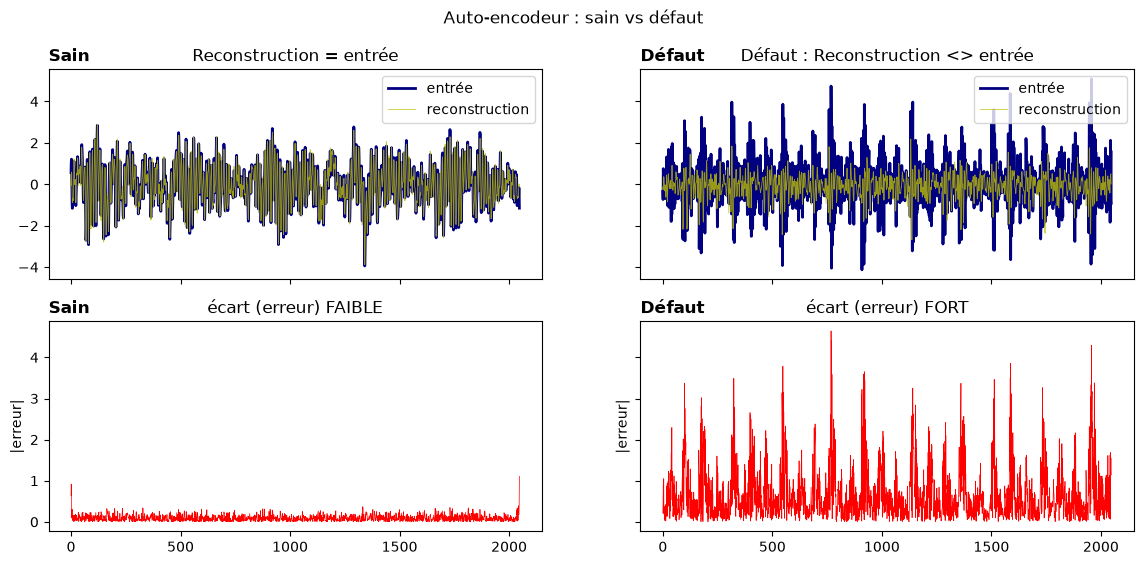

In [12]:
def montrer_reconstruction(i_sain, i_defaut):
    fig, ax = plt.subplots(2, 2, figsize=(14, 6), sharex=True, sharey="row")
    for j, i in enumerate([i_sain, i_defaut]):
        x = SBNorm[i]
        xr = modele.predict(x[None, :, None], verbose=0)[0, :, 0]
        ax[0, j].plot(x, label="entrée", lw=2, color="navy"); ax[0, j].plot(xr, label="reconstruction", alpha=0.8, lw=0.6, color="y")
        ax[0, j].legend()
        ax[1, j].plot(np.abs(x - xr), color="red", lw=0.5); ax[1, j].set_ylabel("|erreur|")
    fig.suptitle("Auto-encodeur : sain vs défaut")
    ax[0, 0].set_title("Sain", loc="left", fontweight="bold");ax[1, 0].set_title("Sain", loc="left", fontweight="bold")
    ax[0, 1].set_title("Défaut", loc="left", fontweight="bold");ax[1, 1].set_title("Défaut", loc="left", fontweight="bold")
    ax[0, 0].set_title("Reconstruction = entrée", loc="center");ax[0, 1].set_title("Défaut : Reconstruction <> entrée", loc="center")
    ax[1, 0].set_title("écart (erreur) FAIBLE", loc="center");ax[1, 1].set_title("écart (erreur) FORT", loc="center")
    plt.show()

montrer_reconstruction(i_train[sain[i_train]][0], i_test[~sain[i_test]][0])

In [13]:
# Evaluation simple sur le test : sain vs defaut score roc_auc_score
from sklearn.metrics import roc_auc_score

y_test = (infos["defaut"].to_numpy()[i_test] != "Sain")             # 0 = sain, 1 = defaut
auc = roc_auc_score(y_test, infos["score"].to_numpy()[i_test])
print(f"ROC-AUC detection sain/defaut : {auc:.3f}")
print("Score très élevé car les données sont 'clairement' saines ou en défaut, le modèle ne se trompe pas")
print("Cela signifie que le modèle distingue à 100% les sains des défauts (on ne tient pas compte du seuil pour ce score)")

ROC-AUC detection sain/defaut : 1.000
Score très élevé car les données sont 'clairement' saines ou en défaut, le modèle ne se trompe pas
Cela signifie que le modèle distingue à 100% les sains des défauts (on ne tient pas compte du seuil pour ce score)


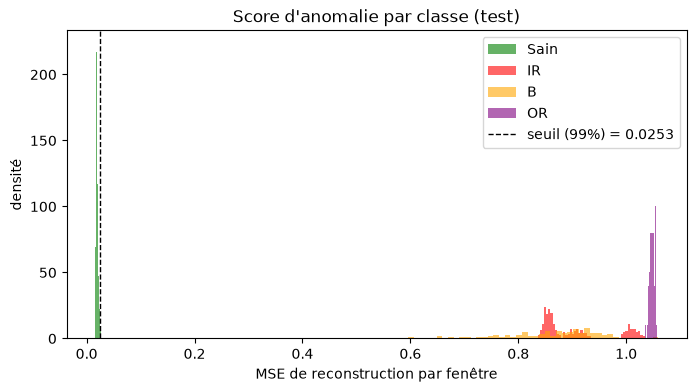

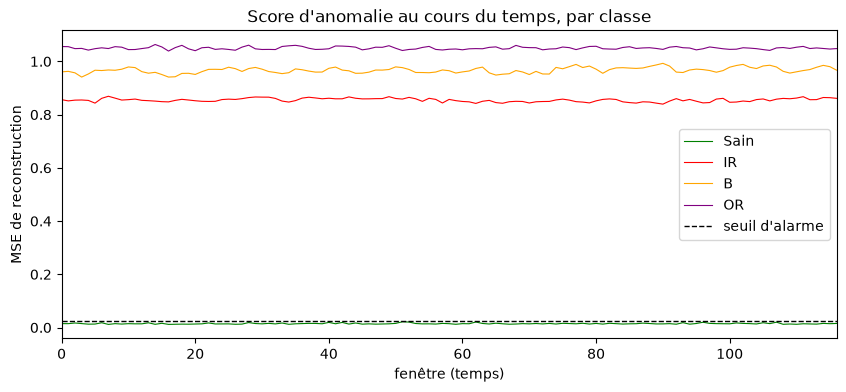

In [14]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import roc_curve, roc_auc_score

# FIGURE 2 : distribution du score d'anomalie (MSE par fenêtre)
scores = infos["score"].to_numpy()
plt.figure(figsize=(8, 4))
for classe, couleur in [("Sain", "green"), ("IR", "red"), ("B", "orange"), ("OR", "purple")]:
    m = infos["defaut"].to_numpy()[i_test] == classe
    plt.hist(scores[i_test][m], bins=50, density=True, alpha=0.6, label=classe, color=couleur)
plt.axvline(seuil, color="black", ls="--", lw=1, label=f"seuil ({seuilPourcent}%) = {seuil:.4f}")
plt.xlabel("MSE de reconstruction par fenêtre"); plt.ylabel("densité")
plt.title("Score d'anomalie par classe (test)")
plt.legend(); plt.show()

# FIGURE 3 : MSE dans le temps pour un fichier défaut du test
palette = {"Sain": "green", "IR": "red", "B": "orange", "OR": "purple"}
plt.figure(figsize=(10, 4))
x_max = np.inf
for classe in ["Sain", "IR", "B", "OR"]:
    noms = infos[infos["defaut"] == classe]["fichier"].unique()
    if len(noms) == 0:
        continue
    nom = noms[0]                                   # 1 fichier par classe
    m = (infos["fichier"] == nom).to_numpy()
    plt.plot(infos.loc[m, "fenetre"], infos.loc[m, "score"], lw=0.8, color=palette[classe], label=classe)
    x_max = min(x_max, infos.loc[m, "fenetre"].max())   # X max = fichier le plus court tracé
plt.xlim(0, x_max)
plt.axhline(seuil, color="black", ls="--", lw=1, label="seuil d'alarme")
plt.xlabel("fenêtre (temps)"); plt.ylabel("MSE de reconstruction")
plt.title("Score d'anomalie au cours du temps, par classe")
plt.legend(); plt.show()

In [15]:
from sklearn.metrics import confusion_matrix
y_true = (infos["defaut"].to_numpy()[i_test] != "Sain").astype(int)   # 0=sain, 1=défaut
y_pred = (infos["score"].to_numpy()[i_test] > seuil).astype(int)

print("=== Matrice de confusion ===")
display(pd.DataFrame(confusion_matrix(y_true, y_pred, labels=[0, 1]), index=["réel sain", "réel défaut"], columns=["prédit sain", "prédit défaut"]))
print("On a quelques faux positif, à cause du seuil")

=== Matrice de confusion ===


,prédit sain,prédit défaut
réel sain,925,19
réel défaut,0,940


On a quelques faux positif, à cause du seuil


In [16]:
from sklearn.metrics import confusion_matrix

y_true = (infos["defaut"].to_numpy()[i_test] != "Sain").astype(int)   # 1 = défaut
y_pred = (infos["score"].to_numpy()[i_test] > seuil).astype(int)      # 1 = alarme

TN, FP, FN, TP = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
print(f"FPR (fausses alarmes, sains détectés défaut) : {FP/(FP+TN):.2%}")
print(f"FNR (défauts manqués, défauts prédits sains)  : {FN/(FN+TP):.2%}")
print("=> Aucun défaut prédit sain, c'est exactement ce qu'on veut pour la détection d'anomalie")

FPR (fausses alarmes, sains détectés défaut) : 2.01%
FNR (défauts manqués, défauts prédits sains)  : 0.00%
=> Aucun défaut prédit sain, c'est exactement ce qu'on veut pour la détection d'anomalie
